<a href="https://colab.research.google.com/github/Ghoul2001/Pr-ctica-02-Preprocesamiento-De-Datos/blob/main/Practica_02_Preprocesamiento_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#***Práctica 02: Preprocesamiento De Datos***

#Christian Carrión López
#23/10/2026

#***ACTIVIDADES A DESARROLLAR:***

In [20]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt
print('Todas las librerías cargadas correctamente')

Todas las librerías cargadas correctamente


#***FASE 1. Anatomía de un Dataset***

In [21]:
import numpy as np
import pandas as pd

datos = {
    'nombre':         ['Ana', 'Luis', 'María', 'Carlos', 'Sofía', 'Diego'],
    'edad':           [21, 23, 20, 25, 22, 21],
    'promedio_gpa':   [8.9, 7.4, 9.5, 6.1, 8.2, 7.8],
    'horas_estudio':  [18, 10, 22, 6, 15, 12],
    'distancia_km':   [2.5, 15.0, 0.8, 40.2, 5.1, 8.7],
    'carrera':        ['Computación', 'Computación', 'Redes', 'Redes', 'Computación', 'Redes'],
    'nivel_ingles':   ['Básico', 'Intermedio', 'Avanzado', 'Básico', 'Avanzado', 'Intermedio'],
    'beca':           [1, 0, 1, 0, 1, 0],
    'aprobado':       ['Si', 'No', 'Si', 'No', 'Si', 'No']
}

df = pd.DataFrame(datos)
print(df)
print(f"\nDimensiones del dataset: {df.shape}")
print(df)
print(f"\nDimensiones del dataset: {df.shape}")

   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computación   
2   María    20           9.5             22           0.8        Redes   
3  Carlos    25           6.1              6          40.2        Redes   
4   Sofía    22           8.2             15           5.1  Computación   
5   Diego    21           7.8             12           8.7        Redes   

  nivel_ingles  beca aprobado  
0       Básico     1       Si  
1   Intermedio     0       No  
2     Avanzado     1       Si  
3       Básico     0       No  
4     Avanzado     1       Si  
5   Intermedio     0       No  

Dimensiones del dataset: (6, 9)
   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computa

#***Actividad 1.1***

* **P1:** El dataset tiene 6 instancias (filas). Cada instancia representa a un estudiante del mundo real con sus características.

* **P2:** Los atributos son: nombre, edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca, aprobado. El label es 'aprobado'. Los features son el resto (excluyendo nombre).

* **P3:** La columna 'nombre' no debería ser un feature porque funciona como identificador único y no aporta patrones generalizables para Machine Learning.

#***Actividad 1.2:***

In [22]:
clasificacion = {
    'columna': ['edad', 'promedio_gpa', 'horas_estudio', 'distancia_km', 'carrera', 'nivel_ingles', 'beca', 'aprobado'],
    'cuantitativa_o_cualitativa': ['Cuantitativa', 'Cuantitativa', 'Cuantitativa', 'Cuantitativa', 'Cualitativa', 'Cualitativa', 'Cualitativa', 'Cualitativa'],
    'discreta_o_continua': ['Discreta', 'Continua', 'Discreta', 'Continua', 'NA', 'NA', 'NA', 'NA'],
    'nominal_u_ordinal': ['NA', 'NA', 'NA', 'NA', 'Nominal', 'Ordinal', 'Nominal', 'Nominal']
}
df_tipos = pd.DataFrame(clasificacion)
print(df_tipos)

         columna cuantitativa_o_cualitativa discreta_o_continua  \
0           edad               Cuantitativa            Discreta   
1   promedio_gpa               Cuantitativa            Continua   
2  horas_estudio               Cuantitativa            Discreta   
3   distancia_km               Cuantitativa            Continua   
4        carrera                Cualitativa                  NA   
5   nivel_ingles                Cualitativa                  NA   
6           beca                Cualitativa                  NA   
7       aprobado                Cualitativa                  NA   

  nominal_u_ordinal  
0                NA  
1                NA  
2                NA  
3                NA  
4           Nominal  
5           Ordinal  
6           Nominal  
7           Nominal  


* **P4:** 'nivel_ingles' es cualitativa ordinal porque sus valores tienen jerarquía. Importa al entrenar porque permite usar Ordinal Encoding.

* **P5:** 'beca' es cualitativa nominal (binaria). Aunque use 0 y 1, representan ausencia/presencia; no tiene sentido calcular su media matemática.

#***Actividad 1.3***

In [23]:
print('Tipos de datos detectados por pandas:')
print(df.dtypes)
print('\nEstadísticas descriptivas:')
print(df.describe())

Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas:
            edad  promedio_gpa  horas_estudio  distancia_km      beca
count   6.000000      6.000000       6.000000       6.00000  6.000000
mean   22.000000      7.983333      13.833333      12.05000  0.500000
std     1.788854      1.192337       5.741661      14.68615  0.547723
min    20.000000      6.100000       6.000000       0.80000  0.000000
25%    21.000000      7.500000      10.500000       3.15000  0.000000
50%    21.500000      8.000000      13.500000       6.90000  0.500000
75%    22.750000      8.725000      17.250000      13.42500  1.000000
max    25.000000      9.500000      22.000000      40.20000  1.000000


* **P6:** No siempre coinciden. Pandas clasifica 'beca' como int64, pero conceptualmente es cualitativa nominal.

* **P7:** 'distancia_km' tiene mayor dispersión. Si se usa KNN sin escalar, esta columna dominará el cálculo de distancia y sesgará el modelo.

#***Actividad 2.1 y 2.2***

In [24]:
# Extraemos SOLO las columnas numéricas continuas para esta fase
columnas_numericas = ["promedio_gpa", "horas_estudio", "distancia_km"]
X = df[columnas_numericas].values.astype(float)
print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape} - {X.shape[0]} instancias, {X.shape[1]} features")

def min_max_manual(X):
    # Normalización Min-Max: transforma cada columna al rango [0, 1]
    # Fórmula: x' = (x - min) / (max - min)
    X_min = X.min(axis=0) # mínimo por columna
    X_max = X.max(axis=0) # máximo por columna
    X_norm = (X - X_min) / (X_max - X_min)
    return X_norm, X_min, X_max

X_minmax, mins, maxs = min_max_manual(X)
print("\n=== RESULTADO MIN-MAX ===")
print(f"{'Feature':<18} {'Min original':>14} {'Max original':>14}")
print("-" * 48)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {mins[i]:>14.2f} {maxs[i]:>14.2f}")

print("\nDatos normalizados (Min-Max):")
df_minmax = pd.DataFrame(X_minmax, columns=[c+"_mm" for c in columnas_numericas])
print(df_minmax.round(4))

Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3) - 6 instancias, 3 features

=== RESULTADO MIN-MAX ===
Feature              Min original   Max original
------------------------------------------------
promedio_gpa                 6.10           9.50
horas_estudio                6.00          22.00
distancia_km                 0.80          40.20

Datos normalizados (Min-Max):
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005


* **P8:** Se excluyen edad (discreta) y beca (nominal). Escalar beca no tiene sentido porque ya representa clases estáticas.

* **P9:** Mínimo 0.0 y máximo 1.0. El 0.0 es el valor más bajo original, 1.0 es el más alto.

* **P10:** Si agregamos 80 km, el rango cambia y los demás valores se comprimirán hacia el 0. La varianza original se aplasta.

#***Actividad 2.3***

In [25]:
def zscore_manual(X):
    # Z-Score: transforma cada columna a media = 0 y desv.est. = 1
    # Fórmula: z = (x - media) / desviacion_estandar
    media = X.mean(axis=0)
    std = X.std(axis=0) # desviación estándar de la población
    X_z = (X - media) / std
    return X_z, media, std

X_zscore, medias, stds = zscore_manual(X)
print("=== RESULTADO Z-SCORE ===")
print(f"{'Feature':<18} {'Media':>10} {'Desv. Est.':>12}")
print("-" * 42)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {medias[i]:>10.3f} {stds[i]:>12.3f}")

print("\nDatos estandarizados (Z-Score):")
df_z = pd.DataFrame(X_zscore, columns=[c+"_z" for c in columnas_numericas])
print(df_z.round(4))

=== RESULTADO Z-SCORE ===
Feature                 Media   Desv. Est.
------------------------------------------
promedio_gpa            7.983        1.088
horas_estudio          13.833        5.241
distancia_km           12.050       13.407

Datos estandarizados (Z-Score):
   promedio_gpa_z  horas_estudio_z  distancia_km_z
0          0.8422           0.7950         -0.7123
1         -0.5359          -0.7314          0.2200
2          1.3934           1.5581         -0.8391
3         -1.7303          -1.4945          2.0997
4          0.1991           0.2226         -0.5184
5         -0.1684          -0.3498         -0.2499


* **P12:** Un Z-Score negativo significa que el dato está por debajo de la media del grupo, no que estudie mal.

* **P13:** Z-Score es más informativo para la 'rareza' (40 km) porque indica a cuántas desviaciones estándar de la media está, resaltando la anomalía mejor que el tope 1.0 de Min-Max.

#***Actividades 2.4 y 2.5***

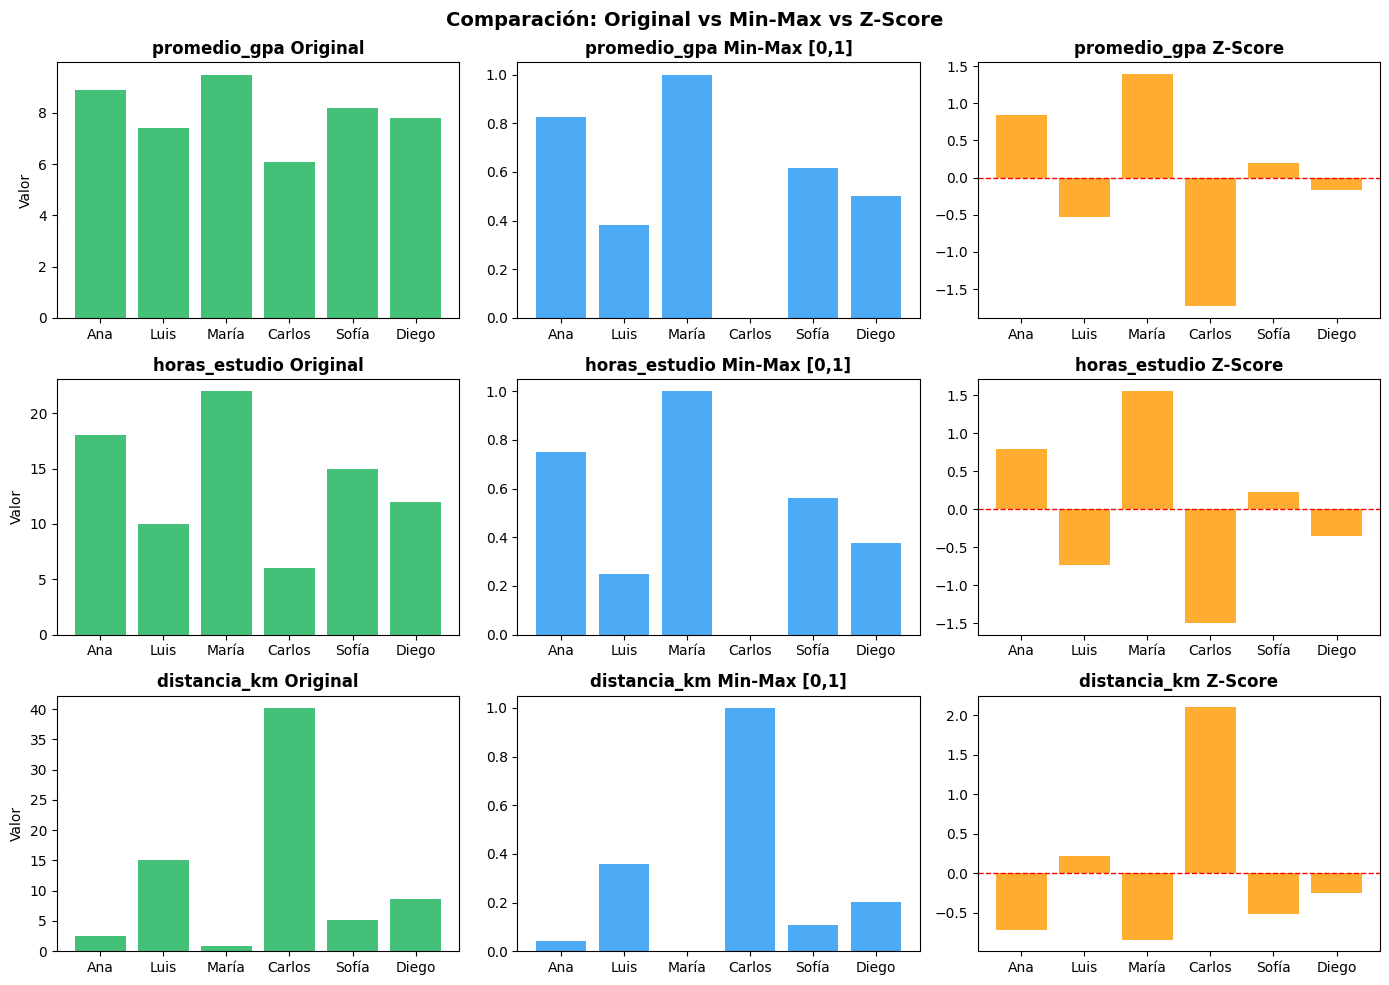

=== Columna distancia_km con outlier (120 km) ===

Estudiante   Original    Min-Max    Z-Score
--------------------------------------------
Ana               2.5     0.0143    -0.6280
Luis             15.0     0.1191    -0.3137
María             0.8     0.0000    -0.6708
Carlos           40.2     0.3305     0.3201
Sofía             5.1     0.0361    -0.5626
Diego             8.7     0.0663    -0.4721
Nuevo           120.0     1.0000     2.3271


In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
nombres = df["nombre"].values

for i, col in enumerate(columnas_numericas):
    # Original
    axes[i, 0].bar(nombres, X[:, i], color="#15B158", alpha=0.8)
    axes[i, 0].set_title(f"{col} Original", fontweight='bold')
    axes[i, 0].set_ylabel("Valor")

    # Min-Max
    axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3", alpha=0.8)
    axes[i, 1].set_title(f"{col} Min-Max [0,1]", fontweight='bold')

    # Z-Score
    axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800", alpha=0.8)
    axes[i, 2].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[i, 2].set_title(f"{col} Z-Score", fontweight='bold')

plt.suptitle("Comparación: Original vs Min-Max vs Z-Score", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Añadimos un estudiante con una distancia extrema
X_con_outlier = np.vstack([X, [8.5, 14, 120.0]]) # 120 km
X_mm_con_outlier, _ , _ = min_max_manual(X_con_outlier)
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

print("=== Columna distancia_km con outlier (120 km) ===")
print(f"\n{'Estudiante':<10} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 44)
nombres_ext = list(nombres) + ["Nuevo"]
for j in range(len(nombres_ext)):
    print(f"{nombres_ext[j]:<10} {X_con_outlier[j,2]:>10.1f} {X_mm_con_outlier[j, 2]:>10.4f} {X_z_con_outlier[j,2]:>10.4f}")

* **P14:** Sí, las proporciones relativas se mantienen exactamente igual visualmente. Lo único que cambia es el rango numérico (la escala) de los ejes.

* **P15:** Al agregar 120 km, Min-Max comprime notoriamente a todos los demás estudiantes hacia valores cercanos a 0. Z-Score es más robusto porque se centra en la media y desviación típica, mitigando en parte el aplastamiento total, aunque una técnica aún mejor y más resiliente a outliers extremos es el RobustScaler que utiliza la mediana y el rango intercuartílico.

#***Fase 3 - Palmer Penguins***

In [27]:
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
print("=== PRIMERA VISTA DEL DATASET ===")
print(df_penguins.head())
print(f"\nDimensiones: {df_penguins.shape}")

print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)
print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())
print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_penguins.describe())

=== PRIMERA VISTA DEL DATASET ===
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  

Dimensiones: (344, 8)

=== TIPOS DE DATOS ===
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

=== VALORES NULOS ===
species            

* **P16:** El dataset tiene 344 instancias originales. Features numéricas: "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g". El label más lógico sería predecir la especie (species).

* **P17:** Hay valores nulos. Es crucial tratarlos porque las transformaciones matemáticas de escalado calculan promedios, máximos o mínimos; la presencia de NaN generaría errores de cálculo matemático impidiendo compilar la matriz.

* **P18:** Variables como sex e island son nominales categóricas. Si ordenáramos las islas por temperatura, podríamos argumentar un tratamiento de variable ordinal, pero en su estado natural son netamente nominales geográficas.

* **P19:** body_mass_g dominaría masivamente el cálculo de distancias por tener valores en miles (~3500-6000), frente a profundidades en milímetros (13-21). Esto es injusto biológicamente porque no refleja la real importancia de la varianza del pico frente a la masa.

* **P20:** El escalado NO cambia la forma de la distribución. Esto es importante porque las propiedades estadísticas subyacentes (normalidad) no se pierden tras escalar.

* **P21:** body_mass_g presenta asimetrías u outliers pronunciados, no se asemeja perfectamente a una campana de Gauss, lo cual condiciona la elección hacia métodos que no asuman normalidad perfecta (RobustScaler o MinMax).

#***Fase 4 - Hugging Face + sklearn***

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

df_clean = df_penguins.dropna()
features_num = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = df_clean[features_num].values

# División Train/Test
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape} - {X_train.shape[0]} pingüinos")
print(f"Test: {X_test.shape} - {X_test.shape[0]} pingüinos")

# Aplicando escaladores
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()

X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)

X_test_mm = mm_scaler.transform(X_test)
X_test_zs = zs_scaler.transform(X_test)
X_test_rb = rb_scaler.transform(X_test)

print("\nParámetros aprendidos por MinMaxScaler (sobre train):")
print(f" Mínimos: {mm_scaler.data_min_.round(2)}")
print(f" Máximos: {mm_scaler.data_max_.round(2)}")

print("\nParámetros aprendidos por StandardScaler (sobre train):")
print(f" Medias: {zs_scaler.mean_.round(2)}")
print(f" Std: {zs_scaler.scale_.round(2)}")

print("\nParámetros aprendidos por RobustScaler (sobre train):")
print(f" Medianas: {rb_scaler.center_.round(2)}")
print(f" IQR: {rb_scaler.scale_.round(2)}")

Train: (266, 4) - 266 pingüinos
Test: (67, 4) - 67 pingüinos

Parámetros aprendidos por MinMaxScaler (sobre train):
 Mínimos: [  32.1   13.1  172.  2700. ]
 Máximos: [  59.6   21.5  231.  6050. ]

Parámetros aprendidos por StandardScaler (sobre train):
 Medias: [  44.08   17.07  201.41 4232.61]
 Std: [  5.41   1.97  14.24 809.57]

Parámetros aprendidos por RobustScaler (sobre train):
 Medianas: [  44.9   17.2  197.  4100. ]
 IQR: [   8.9    3.2   24.  1200. ]


* **P23(primera):** Se divide antes del escalado para evitar Data Leakage (Fuga de datos). Si se escala primero, la información global del test (mínimos, máximos, promedios) "contaminaría" al modelo en entrenamiento, dándole ventaja estadística sobre datos que el algoritmo no debería haber visto aún.

* **P22(segunda):** Los parámetros de MinMaxScaler calculados en Scikit-Learn coinciden conceptualmente con los cálculos manuales usando NumPy mostrados en la Fase 2. Las mínimas variaciones numéricas decimales (si existen) ocurren por la precisión de punto flotante subyacente.

#***CONCLUSIONE***

A partir del desarrollo de esta práctica, pude darme cuenta de que el preprocesamiento es un paso crítico y no solo un trámite rápido antes de entrenar un modelo. Uno de los puntos que más me llamó la atención fue ver cómo las librerías como pandas pueden equivocarse desde el punto de vista conceptual al asignar los tipos de datos (como ocurrió con la variable "beca", que la detectó como numérica solo por tener 0 y 1). Esto me enseñó que no puedo confiar a ciegas en las herramientas sin aplicar primero mi propio criterio analítico.